# 07. Optimasi RTX 5070 dan training nyata

Sesi AI-012, 13 Oktober 2026. Notebook default membaca bukti aktual, tanpa training otomatis.
Alur: environment, empat sweep terpisah, operator CUDA aktual, pemilihan batch48, training800update, development, dan telemetry.
Skor throughput berbeda dari kualitas model. Finalv5 belum dibuka. Prompt/model lama dan log lama dipertahankan.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
def read(path): return json.loads((ROOT/path).read_text(encoding='utf-8'))
print('Active interpreter:',sys.executable)
print('Recorded training environment:')
display(read('reports/training/GPU-PERF-001_environment.json'))

Active interpreter: F:\Generative_AI\Vibe_Coding_Proyek_1\.venv\Scripts\python.exe
Recorded training environment:


{'python': '3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]',
 'interpreter': 'F:\\Generative_AI\\Vibe_Coding_Proyek_1\\.venv\\Scripts\\python.exe',
 'torch': '2.14.1+cu130',
 'cuda': '13.0',
 'gpu': 'NVIDIA GeForce RTX 5070',
 'vram_bytes': 12820480000,
 'cuda_available': True,
 'bf16': True,
 'capability': [12, 0],
 'platform': 'Windows-10-10.0.26200-SP0',
 'disk_free_bytes': 20554289152,
 'nvidia_smi': 'name, memory.total [MiB], memory.used [MiB], utilization.gpu [%], power.draw [W], power.limit [W], temperature.gpu\nNVIDIA GeForce RTX 5070, 12227 MiB, 3224 MiB, 2 %, 18.44 W, 250.00 W, 43\n'}

## 1. Perbandingan nyata, termasuk kandidat yang ditolak

Bobot probe dibuang. Input train saja, enam warmup, 40/200/100/100 update terukur tiap case. Perubahan batch/backend menyebabkan trajectory berbeda. Memori total nvidia-smi mencakup desktop.

In [2]:
profiles = [read(f'reports/training/GPU-PERF-{i:03d}.json') for i in range(1,5)]
rows=[]
for i,profile in enumerate(profiles,1):
    for row in profile['cases']:
        rows.append({'sweep':i,'case':row['case'],'status':row['status'],
            'target_tokens_s':row.get('target_tokens_per_second'),
            'allocated_GiB':row.get('peak_allocated_bytes',0)/2**30,
            'reserved_GiB':row.get('peak_reserved_bytes',0)/2**30,
            'free_GiB':row.get('free_vram_bytes',0)/2**30,
            'GPU_mean_pct':row.get('telemetry',{}).get('utilization_pct',{}).get('mean')})
display(pd.DataFrame(rows))
print('Selection:',profiles[-1]['selected']['case'])

,sweep,case,status,target_tokens_s,allocated_GiB,reserved_GiB,free_GiB,GPU_mean_pct
0,1,manual_b4_a2,completed,28222.619734,2.091867,2.333984,8.391602,90.000000
1,1,sdpa_b4_a2,completed,68723.535787,1.101852,1.191406,9.534180,63.250000
2,1,sdpa_b8_a1,completed,73201.326761,1.831321,1.984375,8.741211,62.333333
3,1,sdpa_b16_a1,completed,83823.397255,3.395469,3.822266,6.903320,84.333333
4,1,sdpa_b24_a1,completed,85379.352029,4.956626,5.662109,5.063477,90.875000
5,1,sdpa_b32_a1,completed,87506.276035,6.519432,7.505859,1.920898,94.800000
6,1,sdpa_b48_a1,completed,64258.830636,9.649436,11.207031,0.000000,95.150000
7,2,manual_b4_a2,completed,29006.469234,2.091867,2.333984,8.391602,89.702703
8,2,sdpa_b24_a1,completed,85248.658995,4.956626,5.662109,5.063477,92.000000
9,2,sdpa_b32_a1,completed,87001.645796,6.519432,7.505859,3.219727,93.200000


Selection: packed_b48_a1


## 2. Backend dan pengaturan yang benar-benar digunakan

SDPA auto dispatch memakai memory-efficient attention CUTLASS dalam operator profiling ini, bukan klaim FlashAttention. Optimizer fused tercatat. Expandable segments mengurangi reserved VRAM pada ukuran target yang bervariasi.

In [3]:
operators=read('reports/training/GPU-PERF-001_attention_operators.json')
display(pd.DataFrame(operators['operators']))
config=read('configs/training_gpu_optimized.json')
display(config)

,name,calls
0,Optimizer.zero_grad#AdamW.zero_grad,1
1,aten::scaled_dot_product_attention,6
2,aten::_scaled_dot_product_efficient_attention,6
3,aten::_efficient_attention_forward,6
4,_Z40fmha_cutlassF_bf16_aligned_64x64_rf_sm80N2...,6
5,autograd::engine::evaluate_function: ScaledDot...,6
6,ScaledDotProductEfficientAttentionBackward0,6
7,aten::_scaled_dot_product_efficient_attention_...,6
8,aten::_efficient_attention_backward,6
9,_Z49fmha_cutlassB_bf16_aligned_64x64_k64_dropo...,6


{'mode': 'sft',
 'data_origin': 'synthetic_curriculum',
 'human_reviewed': False,
 'curriculum_continuation': True,
 'dataset_dir': 'data/processed/curriculum/v5',
 'seed': 42,
 'block_size': 1024,
 'tokenizer': 'data/tokenizer/tokenizer.json',
 'model_config_path': 'configs/model.json',
 'device': 'cuda',
 'precision': 'bf16',
 'batch_size': 48,
 'gradient_accumulation': 1,
 'max_steps': 800,
 'warmup_steps': 40,
 'learning_rate': 2e-05,
 'min_learning_rate': 2e-06,
 'betas': [0.9, 0.95],
 'weight_decay': 0.1,
 'grad_clip': 1.0,
 'validation_interval': 160,
 'validation_batches': 30,
 'checkpoint_interval': 160,
 'log_interval': 80,
 'reserve_free_bytes': 16106127360,
 'performance': {'attention_backend': 'sdpa',
  'fused_adamw': True,
  'pin_memory': True,
  'tf32': True,
  'supervised_only_logits': True,
  'allocator_config': 'expandable_segments:True',
  'gpu_telemetry': True,
  'selected_by': 'reports/training/GPU-PERF-004.json'},
 'experiment_scope': 'GPU optimized continuation; 

## 3. Checkpoint, data, dan training

Model14.186.496parameter tetap dari bobot acak proyek. Continuation memulai optimizer/schedule baru dari TRAIN-012best, bukan resume state optimizer. Target JSON/EOS aktif, prompt/padding masked. Tidak ada name16x pada run ini. Sintetis bukan anotasi reviewed produksi.

In [4]:
run=read('reports/training/TRAIN-014.json')
performance=read('reports/training/TRAIN-014_gpu_performance.json')
display({key:run.get(key) for key in ('status','global_step','wall_seconds','parameter_count','initial_validation','final_validation','best_validation_loss','best_checkpoint','performance','environment')})
display(run['config']['lineage'])

{'status': 'completed',
 'global_step': 800,
 'wall_seconds': 162.2572570000193,
 'parameter_count': 14186496,
 'initial_validation': {'loss': 0.005657631831054099,
  'perplexity': 1.0056736664550927,
  'valid_tokens': 623706,
  'batches': 30},
 'final_validation': {'loss': 0.0057741252896185225,
  'perplexity': 1.0057908276828111,
  'valid_tokens': 623706,
  'batches': 30},
 'best_validation_loss': 0.005657631831054099,
 'best_checkpoint': {'path': 'checkpoints\\TRAIN-014\\.versions\\best-37cb6852be694a40a565a0ee704fb375.pt',
  'payload': '.versions\\best-37cb6852be694a40a565a0ee704fb375.pt',
  'sha256': '0c7a4dae3ecc2b4801846727a91928e4ad3166a837cf1c16d158ccf288aaebfe',
  'global_step': 0,
  'validation_loss': 0.005657631831054099},
 'performance': {'attention_backend': 'sdpa',
  'fused_adamw': True,
  'pin_memory': True,
  'tf32': True,
  'supervised_only_logits': True,
  'allocator_config': 'expandable_segments:True',
  'gpu_telemetry': True,
  'selected_by': 'reports/training/GPU-

{'tokenizer_sha256': 'f7d5410d5963b3504bc09a4f6bf29e695cb8c6ba64041bfe1596a13cecb210d7',
 'pretrain_fingerprint': {'version': 1,
  'tokenizer_sha256': 'f7d5410d5963b3504bc09a4f6bf29e695cb8c6ba64041bfe1596a13cecb210d7',
  'assignment_sha256': 'b827fdf80f0a20577a674a2ef4b70159da92a472e2535d5458c410c0398ab55b',
  'source_revisions': [{'id': 'vulcan',
    'revision': '19d2a482c78554e59feca0ce2b50fb7835e90c6f',
    'license': 'mit',
    'rows': 5000},
   {'id': 'websight_v01',
    'revision': 'b11f8172f89c992b56ac702319e02c428cca4a4e',
    'license': 'cc-by-4.0',
    'rows': 20000},
   {'id': 'websight_v02',
    'revision': 'b11f8172f89c992b56ac702319e02c428cca4a4e',
    'license': 'cc-by-4.0',
    'rows': 30000}],
  'partition_sha256': {'train': '9de281a574a839157549c3334cee4d61a6ef90ccccd81905f04ce89e79ae098b',
   'validation': '4116003f72270f9631ffa42b4d37c403d7adf4a82b4c749194a3dddd51b95bfd',
   'test': 'ecca06285b5c4f67b12146e2a3824ea793a7b2a2797416ab9560f1c30456d9f5'},
  'token_cache_

## 4. Telemetry pada update training

Ringkasan berikut memilih sampel yang waktunya berada di dalam interval update, setelah lima update awal. Checkpoint/validation/idle dipisahkan dari angka active training. Utilisasi maksimum100% tidak berarti setiap saat100%.

In [5]:
display({key:value for key,value in performance.items() if key not in ('curve','all_phase_telemetry')})
print('All-phase telemetry includes validation, checkpoint and startup:')
display(performance['all_phase_telemetry'])

{'run_id': 'TRAIN-014',
 'status': 'completed',
 'warmup_updates_excluded': 5,
 'measured_training_updates': 795,
 'training_step_seconds': 143.92121309950016,
 'target_tokens_per_second': 99199.67107371181,
 'speedup_vs_profile_baseline': 3.4321876470714137,
 'seconds_per_update': 0.18103297245220146,
 'trainer_wall_seconds': 162.2572570000193,
 'total_train_tokens_including_warmup': 14365682,
 'peak_allocated_bytes': 7037730304,
 'peak_reserved_bytes': 7163871232,
 'training_active_telemetry': {'sample_count': 256,
  'utilization_pct': {'mean': 93.23046875, 'max': 100.0, 'min': 1.0},
  'memory_used_mib': {'mean': 8669.87109375, 'max': 8691.0, 'min': 8421.0},
  'power_w': {'mean': 194.998828125, 'max': 201.96, 'min': 114.99},
  'temperature_c': {'mean': 61.36328125, 'max': 67.0, 'min': 52.0},
  'sm_clock_mhz': {'mean': 2922.8984375, 'max': 2940.0, 'min': 2917.0}},
 'initial_validation': {'loss': 0.005657631831054099,
  'perplexity': 1.0056736664550927,
  'valid_tokens': 623706,
  'bat

All-phase telemetry includes validation, checkpoint and startup:


{'sample_count': 287,
 'interval_seconds': 0.5,
 'raw_path': 'F:\\Generative_AI\\Vibe_Coding_Proyek_1\\outputs\\metrics\\TRAIN-014_gpu.jsonl',
 'errors': [],
 'memory_scope': 'nvidia-smi memory includes other desktop applications',
 'utilization_pct': {'mean': 90.68989547038328, 'max': 100.0, 'min': 0.0},
 'memory_used_mib': {'mean': 8514.020905923346, 'max': 8691.0, 'min': 1861.0},
 'power_w': {'mean': 191.79717770034844, 'max': 215.75, 'min': 26.05},
 'temperature_c': {'mean': 60.853658536585364, 'max': 67.0, 'min': 40.0},
 'sm_clock_mhz': {'mean': 2907.8257839721255, 'max': 2947.0, 'min': 870.0}}

## 5. Grafik throughput dan loss aktual

Training dan validation memakai ordinary CE pada corpus berbeda. Grafik tidak membuktikan ketepatan nama/prompt umum.

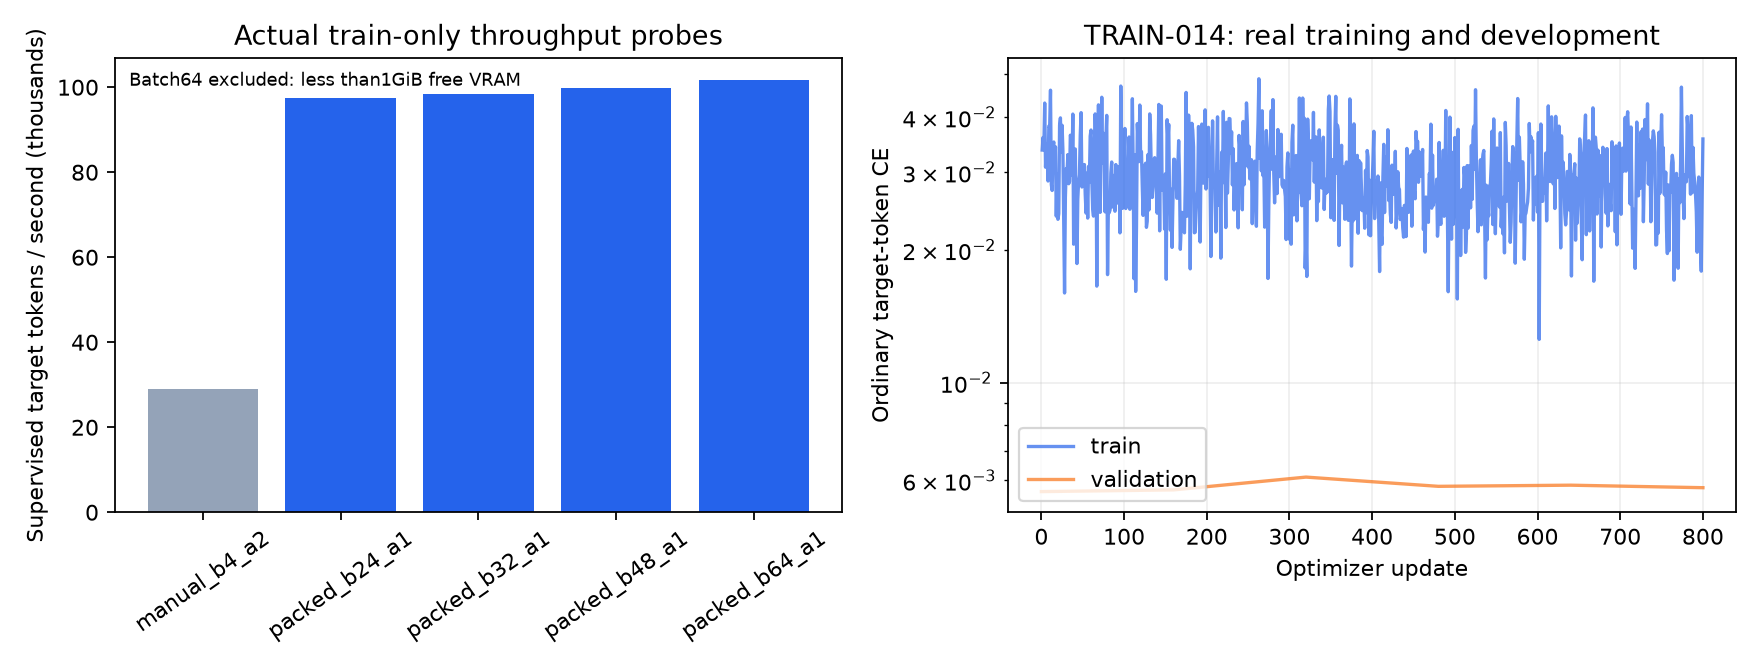

In [6]:
display(Image(filename=str(ROOT/'reports/training/TRAIN-014_gpu_training.png')))

## 6. Development generation dan batas kualitas

Evaluator memakai checkpoint validation-selected, raw JSON tanpa repair, decodegreedy/EOS. Ini development yang sudah pernah dilihat, bukan locked final baru. Model runtime demonstrasi tetap checkpoint historis sampai bukti final baru tersedia.

In [7]:
evaluation=read('reports/training/TRAIN-014-DEV_curriculum_evaluation.json')
display({key:evaluation[key] for key in ('count','schema_valid','exact_contract','exact_field_matches','all_ended_eos','token_metrics','contract_gate_passed')})
print('Finalv5 remains closed; development is not overall production acceptance.')

{'count': 24,
 'schema_valid': 24,
 'exact_contract': 20,
 'exact_field_matches': {'title': 20,
  'style_mode': 24,
  'theme': 24,
  'sections': 20,
  'interactions': 24},
 'all_ended_eos': True,
 'token_metrics': {'loss': 0.005658693507831979,
  'perplexity': 1.0056747341560375,
  'valid_tokens': 623706,
  'batches': 360},
 'contract_gate_passed': False}

Finalv5 remains closed; development is not overall production acceptance.


## 7. Menjalankan eksperimen baru secara eksplisit

RUN_TRAINING=False. True akan memakai GPU dan membuat RUN/TRAIN baru. Jangan jalankan bersamaan dengan training lain. Pertahankan reserve15GiB. Bila aplikasi GPU lain aktif, kurangi batch dan hitung ulang validation_batches agar validation tetap lengkap.

In [8]:
RUN_TRAINING=False
if RUN_TRAINING:
    import subprocess
    subprocess.run([sys.executable,'-m','qa.run_logged','--label','notebook_gpu_optimized_training','--',
        sys.executable,'-m','qa.train_configured_gpu','--config','configs/training_gpu_optimized.json',
        '--initialize-from','checkpoints/TRAIN-012/best.pt'],cwd=ROOT,check=True)
else:
    print('Read-only mode; no training launched.')

Read-only mode; no training launched.
